# AI-Generated Image Detection Using Digital Image Processing and Machine Learning

This revised notebook detects real vs AI-generated images using handcrafted digital image processing features and machine learning.

It includes:
- LBP, FFT, GLCM, and Sobel edge features
- Logistic Regression external baseline
- Optimized SVM proposed model
- Confusion matrix, ROC/AUC, and ablation study


## 1. Import Libraries

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score
)

from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

np.random.seed(42)


## 2. Dataset Loading

In [3]:
dataset_path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")

train_path = os.path.join(dataset_path, "train")
fake_path = os.path.join(train_path, "FAKE")
real_path = os.path.join(train_path, "REAL")

print("Dataset path:", dataset_path)
print("Train folders:", os.listdir(train_path))
print("Number of FAKE images:", len(os.listdir(fake_path)))
print("Number of REAL images:", len(os.listdir(real_path)))


Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.
Dataset path: /kaggle/input/cifake-real-and-ai-generated-synthetic-images
Train folders: ['FAKE', 'REAL']
Number of FAKE images: 50000
Number of REAL images: 50000


In [5]:
import os
import cv2

print("Fake folder:", fake_path)
print("Real folder:", real_path)

for folder_name, folder_path in [
    ("FAKE", fake_path),
    ("REAL", real_path)
]:
    files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    print(f"\n{folder_name}: {len(files)} images")

    for filename in files[:3]:
        img = cv2.imread(os.path.join(folder_path, filename))
        if img is not None:
            print(filename, "->", img.shape[1], "x", img.shape[0])

Fake folder: /kaggle/input/cifake-real-and-ai-generated-synthetic-images/train/FAKE
Real folder: /kaggle/input/cifake-real-and-ai-generated-synthetic-images/train/REAL

FAKE: 50000 images
5387 (6).jpg -> 32 x 32
4093 (7).jpg -> 32 x 32
5357 (8).jpg -> 32 x 32

REAL: 50000 images
4093 (7).jpg -> 32 x 32
3825 (3).jpg -> 32 x 32
4131 (5).jpg -> 32 x 32


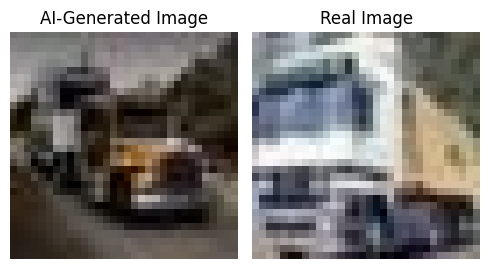

In [7]:
import os
import cv2
import matplotlib.pyplot as plt

fake_image_path = os.path.join(
    fake_path, sorted(os.listdir(fake_path))[0]
)
real_image_path = os.path.join(
    real_path, sorted(os.listdir(real_path))[0]
)

fake_img = cv2.cvtColor(
    cv2.imread(fake_image_path), cv2.COLOR_BGR2RGB
)
real_img = cv2.cvtColor(
    cv2.imread(real_image_path), cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(5, 3))

plt.subplot(1, 2, 1)
plt.imshow(fake_img, interpolation="nearest")
plt.title("AI-Generated Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(real_img, interpolation="nearest")
plt.title("Real Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Preprocessing

In [8]:
def preprocess_image(image_path, image_size=(64, 64)):
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Image could not be read: {image_path}")

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, image_size)
    gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
    gray_norm = gray / 255.0

    return img_resized, gray_norm


## 4. Feature Extraction

In [9]:
def extract_lbp_features(gray_image, radius=1, n_points=8):
    gray_uint8 = (gray_image * 255).astype(np.uint8)
    lbp = local_binary_pattern(gray_uint8, n_points, radius, method="uniform")

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, n_points + 3),
        range=(0, n_points + 2)
    )

    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist


def extract_fft_features(gray_image):
    fft = np.fft.fft2(gray_image)
    fft_shift = np.fft.fftshift(fft)

    magnitude = np.abs(fft_shift)
    power = magnitude ** 2

    h, w = gray_image.shape
    cy, cx = h // 2, w // 2

    y, x = np.ogrid[:h, :w]
    distance = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)

    radius_threshold = min(h, w) * 0.25

    high_freq_energy = power[distance > radius_threshold].sum()
    total_energy = power.sum() + 1e-8
    high_freq_ratio = high_freq_energy / total_energy

    power_norm = power.ravel() / total_energy
    spectral_entropy = -np.sum(power_norm * np.log2(power_norm + 1e-12))

    max_radius = distance.max()
    radial_features = []

    for i in range(4):
        r_min = i * max_radius / 4
        r_max = (i + 1) * max_radius / 4
        band_energy = power[(distance >= r_min) & (distance < r_max)].sum()
        radial_features.append(band_energy / total_energy)

    return np.array([high_freq_ratio, spectral_entropy] + radial_features)


def extract_glcm_features(gray_image):
    gray_uint8 = (gray_image * 255).astype(np.uint8)

    glcm = graycomatrix(
        gray_uint8,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    contrast = graycoprops(glcm, "contrast")[0, 0]
    homogeneity = graycoprops(glcm, "homogeneity")[0, 0]
    energy = graycoprops(glcm, "energy")[0, 0]
    correlation = graycoprops(glcm, "correlation")[0, 0]

    return np.array([contrast, homogeneity, energy, correlation])


def extract_edge_features(gray_image):
    gray_uint8 = (gray_image * 255).astype(np.uint8)

    sobel_x = cv2.Sobel(gray_uint8, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray_uint8, cv2.CV_64F, 0, 1, ksize=3)

    magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

    mean_edge = np.mean(magnitude)
    std_edge = np.std(magnitude)
    max_edge = np.max(magnitude)
    edge_density = np.sum(magnitude > 50) / magnitude.size

    return np.array([mean_edge, std_edge, max_edge, edge_density])


def extract_all_features(image_path):
    _, gray = preprocess_image(image_path)

    lbp = extract_lbp_features(gray)
    fft = extract_fft_features(gray)
    glcm = extract_glcm_features(gray)
    edge = extract_edge_features(gray)

    return np.concatenate([lbp, fft, glcm, edge])


## 5. Feature Dataset Construction

In [10]:
def create_feature_dataset(fake_dir, real_dir, max_images=500):
    X = []
    y = []
    skipped = 0

    fake_images = sorted(os.listdir(fake_dir))[:max_images]
    real_images = sorted(os.listdir(real_dir))[:max_images]

    for img_name in fake_images:
        try:
            img_path = os.path.join(fake_dir, img_name)
            X.append(extract_all_features(img_path))
            y.append(0)  # FAKE
        except Exception:
            skipped += 1

    for img_name in real_images:
        try:
            img_path = os.path.join(real_dir, img_name)
            X.append(extract_all_features(img_path))
            y.append(1)  # REAL
        except Exception:
            skipped += 1

    X = np.array(X)
    y = np.array(y)

    print("Skipped images:", skipped)
    return X, y


X, y = create_feature_dataset(fake_path, real_path, max_images=500)

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Example feature vector length:", len(X[0]))


Skipped images: 0
Feature matrix shape: (1000, 24)
Label vector shape: (1000,)
Example feature vector length: 24


## 6. Train-Test Split and Feature Scaling

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])


Training samples: 800
Testing samples: 200


## 7. External Baseline: Logistic Regression

In [12]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

lr_acc = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

print("LOGISTIC REGRESSION BASELINE")
print("Accuracy :", round(lr_acc, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-score :", round(lr_f1, 4))


LOGISTIC REGRESSION BASELINE
Accuracy : 0.84
Precision: 0.8333
Recall   : 0.85
F1-score : 0.8416


## 8. Proposed Model: SVM with Hyperparameter Optimization

In [13]:
param_grid = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(
    SVC(),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train_scaled, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Accuracy:", grid.best_score_)


Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Parameters: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.835


## 9. Final SVM Evaluation

In [14]:
best_svm = grid.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)

svm_acc = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

print("FINAL SVM RESULTS")
print("Accuracy :", round(svm_acc, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-score :", round(svm_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, target_names=["FAKE", "REAL"]))


FINAL SVM RESULTS
Accuracy : 0.835
Precision: 0.8252
Recall   : 0.85
F1-score : 0.8374

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.85      0.82      0.83       100
        REAL       0.83      0.85      0.84       100

    accuracy                           0.83       200
   macro avg       0.84      0.83      0.83       200
weighted avg       0.84      0.83      0.83       200



## 10. Confusion Matrix

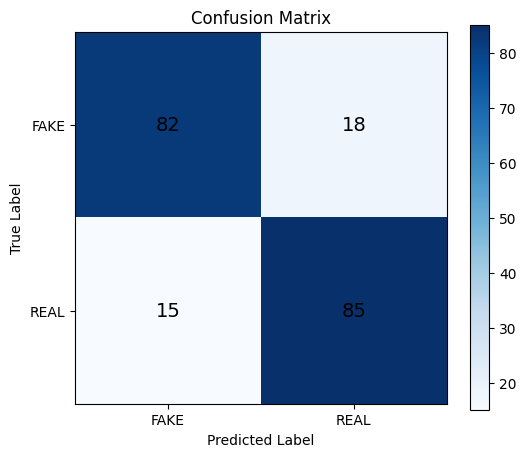

In [15]:
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()

classes = ["FAKE", "REAL"]
plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black", fontsize=14)

plt.show()


## 11. ROC Curve and AUC

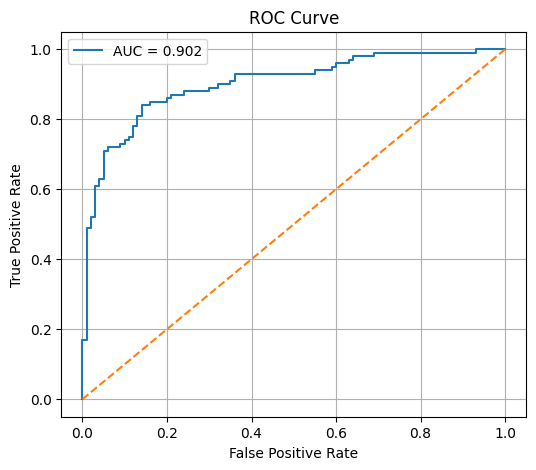

AUC Score: 0.9021


In [16]:
y_scores = best_svm.decision_function(X_test_scaled)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc_score = roc_auc_score(y_test, y_scores)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

print("AUC Score:", round(auc_score, 4))


## 12. Ablation Study

In [17]:
def evaluate_feature_set(X_feature, y, feature_name):
    X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
        X_feature, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    scaler_f = StandardScaler()
    X_train_f = scaler_f.fit_transform(X_train_f)
    X_test_f = scaler_f.transform(X_test_f)

    model = SVC(kernel="rbf", C=10, gamma=0.01)
    model.fit(X_train_f, y_train_f)

    y_pred_f = model.predict(X_test_f)

    acc = accuracy_score(y_test_f, y_pred_f)
    f1 = f1_score(y_test_f, y_pred_f)

    print(f"{feature_name}: Accuracy={acc:.4f}, F1={f1:.4f}")
    return acc, f1


X_lbp = X[:, :10]
X_fft = X[:, 10:16]
X_glcm = X[:, 16:20]
X_edge = X[:, 20:24]
X_combined = X

results = {
    "LBP": evaluate_feature_set(X_lbp, y, "LBP Only"),
    "FFT": evaluate_feature_set(X_fft, y, "FFT Only"),
    "GLCM": evaluate_feature_set(X_glcm, y, "GLCM Only"),
    "Edge": evaluate_feature_set(X_edge, y, "Edge Only"),
    "Combined": evaluate_feature_set(X_combined, y, "Combined Features")
}


LBP Only: Accuracy=0.6150, F1=0.6207
FFT Only: Accuracy=0.7050, F1=0.7256
GLCM Only: Accuracy=0.6950, F1=0.7189
Edge Only: Accuracy=0.7200, F1=0.7308
Combined Features: Accuracy=0.8350, F1=0.8374


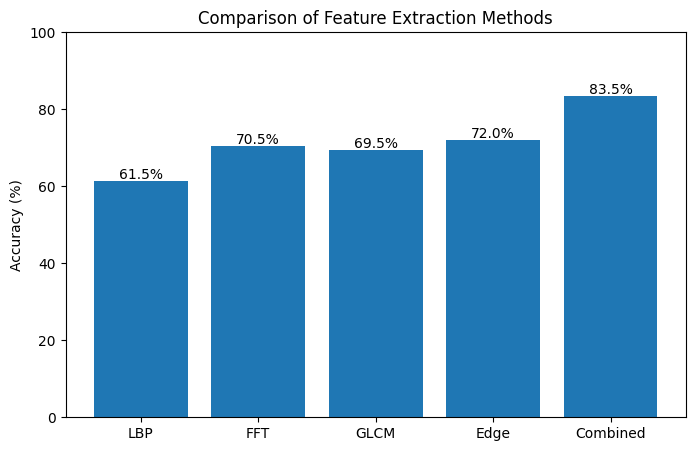

In [18]:
methods = list(results.keys())
accuracies = [results[m][0] * 100 for m in methods]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Comparison of Feature Extraction Methods")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.show()


## 13. Baseline vs Proposed Method Summary

In [19]:
summary_rows = [
    ["Logistic Regression Baseline", lr_acc, lr_f1],
    ["Proposed SVM", svm_acc, svm_f1]
]

print("METHOD COMPARISON")
for method, acc, f1 in summary_rows:
    print(f"{method}: Accuracy={acc:.4f}, F1={f1:.4f}")


METHOD COMPARISON
Logistic Regression Baseline: Accuracy=0.8400, F1=0.8416
Proposed SVM: Accuracy=0.8350, F1=0.8374


In [21]:

import os
import joblib

print("Current directory:", os.getcwd())
print("Directory exists:", os.path.isdir("/kaggle/working"))

# Save to the notebook's current directory
joblib.dump(lr_model, "lr_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model saved:", os.path.exists("lr_model.pkl"))
print("Scaler saved:", os.path.exists("scaler.pkl"))


Current directory: /content
Directory exists: False
Model saved: True
Scaler saved: True


In [22]:

# Check the feature extraction and saved files

import os
import numpy as np
import joblib

print("Model file exists:", os.path.exists("lr_model.pkl"))
print("Scaler file exists:", os.path.exists("scaler.pkl"))

# Test the feature extractor on one image from your dataset
test_image_path = (
    "/kaggle/input/cifake-real-and-ai-generated-synthetic-images/"
    "train/REAL"
)

if os.path.exists(test_image_path):
    image_files = [
        f for f in os.listdir(test_image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
    ]

    if image_files:
        features = extract_all_features(
            os.path.join(test_image_path, image_files[0])
        )
        print("Extracted feature count:", len(features))
        print("Expected feature count:", lr_model.n_features_in_)
    else:
        print("No images found in the REAL folder.")
else:
    print("Dataset path not found. We'll locate the dataset next.")


Model file exists: True
Scaler file exists: True
Extracted feature count: 24
Expected feature count: 24


In [23]:

!pip -q install gradio


In [24]:

import gradio as gr
import numpy as np
import joblib
import os

# Load the saved model and scaler
model = joblib.load("lr_model.pkl")
scaler = joblib.load("scaler.pkl")


def predict_image(image):
    if image is None:
        return {"Please upload an image": 1.0}

    # Save the uploaded image temporarily
    image_path = "/content/uploaded_image.png"

    # Gradio provides the image as a NumPy array
    from PIL import Image
    Image.fromarray(image).save(image_path)

    # Use the same feature extraction as training
    features = extract_all_features(image_path)
    features = np.asarray(features).reshape(1, -1)

    # Apply the training scaler and predict
    features_scaled = scaler.transform(features)
    prediction = model.predict(features_scaled)[0]

    probabilities = model.predict_proba(features_scaled)[0]
    classes = model.classes_

    labels = {
        "FAKE": "AI-Generated",
        "REAL": "Real"
    }

    result = {
        labels.get(str(label).upper(), str(label)): float(probability)
        for label, probability in zip(classes, probabilities)
    }

    return result


demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="numpy", label="Upload an image"),
    outputs=gr.Label(num_top_classes=2, label="Model prediction"),
    title="AI-Generated Image Detector",
    description=(
        "Upload an image to classify it as REAL or AI-GENERATED "
        "using handcrafted image features and Logistic Regression."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6911fa77b2e8ee2162.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:
print("Model classes:", lr_model.classes_)
print("Training labels:", np.unique(y_train))

Model classes: [0 1]
Training labels: [0 1]


In [26]:
print("Label mapping from your dataset:")
print("First few labels:", y[:10])

Label mapping from your dataset:
First few labels: [0 0 0 0 0 0 0 0 0 0]


In [27]:

import inspect

print("=== LABEL CREATION CODE ===")
print(inspect.getsource(preprocess_image) if False else "Check the dataset-loading cell below.")

print("\n=== DATASET LABEL CHECK ===")
print("Unique labels:", np.unique(y))

# Check the original dataset ordering used to construct X and y
print("First 20 labels:", y[:20].tolist())
print("Label counts:", dict(zip(*np.unique(y, return_counts=True))))

# Compare predictions against the actual test labels
print("\n=== TEST LABELS VS PREDICTIONS ===")
print("Model classes:", lr_model.classes_.tolist())
print("Actual labels (first 20):", y_test[:20].tolist())
print("Predicted labels (first 20):", lr_model.predict(X_test_scaled)[:20].tolist())


=== LABEL CREATION CODE ===
Check the dataset-loading cell below.

=== DATASET LABEL CHECK ===
Unique labels: [0 1]
First 20 labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Label counts: {np.int64(0): np.int64(500), np.int64(1): np.int64(500)}

=== TEST LABELS VS PREDICTIONS ===
Model classes: [0, 1]
Actual labels (first 20): [1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0]
Predicted labels (first 20): [1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0]


In [28]:

# Show how your dataset labels were assigned
import glob

for path in glob.glob("/content/**/*.ipynb", recursive=True):
    print("Notebook:", path)


In [29]:

# Identify the REAL/FAKE mapping from your dataset-loading code
import os

print("Check the code that created X and y.")
print("If you loaded REAL first with label 0, then FAKE with label 1:")
print("0 = REAL, 1 = AI-GENERATED")
print("If you loaded FAKE first with label 0, then REAL with label 1:")
print("0 = AI-GENERATED, 1 = REAL")

print("\nYour model's numeric classes:", lr_model.classes_)


Check the code that created X and y.
If you loaded REAL first with label 0, then FAKE with label 1:
0 = REAL, 1 = AI-GENERATED
If you loaded FAKE first with label 0, then REAL with label 1:
0 = AI-GENERATED, 1 = REAL

Your model's numeric classes: [0 1]


In [30]:
import os
import numpy as np

base = "/kaggle/input/cifake-real-and-ai-generated-synthetic-images/train"

for folder in ["REAL", "FAKE"]:
    folder_path = os.path.join(base, folder)
    files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
    ][:100]

    features = [
        extract_all_features(os.path.join(folder_path, f))
        for f in files
    ]

    scaled = scaler.transform(np.asarray(features))
    predictions = lr_model.predict(scaled)

    print(f"{folder} folder: predicted labels {dict(zip(*np.unique(predictions, return_counts=True)))}")

REAL folder: predicted labels {np.int64(0): np.int64(14), np.int64(1): np.int64(86)}
FAKE folder: predicted labels {np.int64(0): np.int64(77), np.int64(1): np.int64(23)}


In [31]:
# Inspect the labels assigned to the first REAL and FAKE images
import os

base = "/kaggle/input/cifake-real-and-ai-generated-synthetic-images/train"

for folder in ["REAL", "FAKE"]:
    files = sorted(os.listdir(os.path.join(base, folder)))
    sample = os.path.join(base, folder, files[0])

    features = extract_all_features(sample).reshape(1, -1)
    scaled = scaler.transform(features)
    pred = lr_model.predict(scaled)[0]

    print(f"Known {folder} image -> model predicted {pred}")

Known REAL image -> model predicted 1
Known FAKE image -> model predicted 0


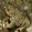

In [32]:
import glob
from PIL import Image
from IPython.display import display

path = glob.glob(
    "/kaggle/input/cifake-real-and-ai-generated-synthetic-images/train/REAL/*"
)[0]

display(Image.open(path))
Image.open(path).save("/content/real_sample.png")